# Utter (Slyším tě): voice commands for people with dysarthria

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TomasZitko/slysim-te/blob/main/notebooks/slysim_te.ipynb)

Regular voice assistants don't understand people with dysarthria (slurred speech after a stroke, with Parkinson's, ALS or cerebral palsy), because they were trained on typical speech.
This notebook tests a simple idea: **a few of the person's own recordings of each word are enough** for a small open model to understand them much better.

**Run in Colab:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all* (about 30–60 minutes). Outputs go to `/content/slysim_te`.
**Locally:** `pip install -r requirements.txt`, run from `notebooks/`. Outputs go to `outputs/`, data and caches to `data/`.

**Data:** TORGO database of dysarthric speech (Rudzicz, Namasivam & Wolff, 2012), Hugging Face copy [`abnerh/TORGO-database`](https://huggingface.co/datasets/abnerh/TORGO-database). 8 speakers with dysarthria, 7 without.

**Why a set of words and not just the 10 commands:** in this version of TORGO, people with dysarthria recorded each command (yes, no, up…) only 1–4 times, mostly once.
That isn't enough to enroll on some recordings and test on the rest. So we simulate a *personal command set*: for each person we repeatedly pick `VOCAB_SIZE` single words
they recorded several times, and measure how well each model tells them apart after 1, 2 or 3 recordings per word.

What the notebook does:
1. Loads TORGO and keeps single words, each recording only once (TORGO records with two microphones at the same time).
2. Turns every recording into a sequence of "fingerprints" with a pre-trained speech model (WavLM).
3. Baseline 1: **Whisper** transcribes the recording; the word counts as recognised if it appears in the transcript.
4. Baseline 2: **other people only**: the same matching, but with recordings of the word by other speakers. No personalisation.
5. Our model: only 1, 2 or 3 of the person's own recordings per word. A new recording is compared with every stored example using
   DTW (dynamic time warping); the word with the closest example wins. The main variant is the **combination**: own recordings + other
   people's recordings of the same word (when they exist). It was chosen on speakers *without* dysarthria only (`experiments/phase2b_hybrid.py`).
6. A **"not sure, say it again"** state: when the model isn't confident, it doesn't guess.
7. Leakage checks, charts, `results.json` for the app, and example recordings.

In [1]:
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:   # locally, packages come from requirements.txt
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-U", "transformers>=4.56", "datasets>=3.0",
                    "accelerate", "soundfile", "librosa", "numba"], check=True)

## 0. Settings
Everything you may want to change is here.

In [2]:
import os
from pathlib import Path

EMB_MODEL = "microsoft/wavlm-base-plus"   # speech model that makes the "fingerprints"
ASR_MODEL = "openai/whisper-small"        # baseline: regular speech recognition
SR = 16000
TRIM_DB = 30            # trim silence at the start and end of each recording
MAX_SECONDS = 6         # a "single word" longer than this (after trimming) is a data error, we drop it

VOCAB_SIZE = 8          # how many words one "command set" has
SHOTS = [1, 2, 3]       # how many recordings per word the model gets for enrollment
REF_SHOT = 2            # the headline number (only a few people have enough words for 3)
N_REPEATS = 50          # how many random word sets / enrollment picks we average over
MIN_OTHER_SPEAKERS = 3  # keep a word only if at least 3 other people said it (for the "other people" model)
MAX_WRONG = 0.05        # max share of wrong actions used to set the "not sure" threshold
LAYER_CANDIDATES = [3, 6, 9, 12]  # WavLM layers; the best one is picked on speakers without dysarthria only
GENERAL_PER_WORD = 10   # "other people" model: max recordings of each word from other speakers
APP_TAKES = 3           # how many recordings per word the app asks for
CONTROL_WHISPER_SAMPLE = 400  # how many recordings of speakers without dysarthria Whisper transcribes (sanity check)
WHISPER_BATCH = 8
WHISPER_MAX_TOKENS = 25 # a single word is short; longer output is a hallucination and only costs time
SEED = 42
RUN_DEMO = False        # True = launches a small Gradio demo at the end

# Commands for the optional Gradio demo (live enrollment with your own voice)
COMMANDS = ["yes", "no", "up", "down", "left", "right", "forward", "back", "select", "menu"]

# Severity comes straight from the dataset's `severity` column
SEVERITY = {"severe": "severe", "moderate-severe": "moderate-severe", "moderate": "moderate",
            "mild": "mild", "typical": "none"}
SEV_ORDER = {"severe": 0, "moderate-severe": 1, "moderate": 2, "mild": 3, "none": 4}

if IN_COLAB:
    OUT_DIR, DATA_DIR = "/content/slysim_te", "/content/data"
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    OUT_DIR, DATA_DIR = str(ROOT / "outputs"), str(ROOT / "data")
CACHE_DIR = f"{DATA_DIR}/cache"   # fingerprints and transcripts, so a re-run doesn't recompute them

## 1. Data
Audio is decoded only for the recordings we keep, so this doesn't take forever.

In [3]:
import io, json, random, re, glob, hashlib
import numpy as np, pandas as pd, soundfile as sf, librosa
from datasets import load_dataset, Audio
from tqdm.auto import tqdm

os.makedirs(f"{OUT_DIR}/examples", exist_ok=True); os.makedirs(CACHE_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

# Locally we use parquet files downloaded to data/raw (if present), otherwise download from Hugging Face
local = sorted(glob.glob(f"{DATA_DIR}/raw/*.parquet"))
ds = (load_dataset("parquet", data_files=local, split="train") if local
      else load_dataset("abnerh/TORGO-database", split="train"))
ds = ds.cast_column("audio", Audio(decode=False))

def parse_name(path):
    # FC01_1_arrayMic_0066.wav -> speaker, session, microphone, utterance number
    p = os.path.splitext(os.path.basename(path))[0].split("_")
    return dict(speaker=p[0], session=p[1], mic=p[2], utt=p[3])

def clean(text):
    return re.sub(r"[^a-z' ]", "", str(text).lower()).strip()

paths = ds.data.table.flatten().column("audio.path").to_pylist()   # paths only, no audio loaded
meta = pd.DataFrame([parse_name(p) for p in paths])
meta["row"] = np.arange(len(meta))
meta["label"] = [clean(t) for t in list(ds["transcription"])]
meta["status"] = list(ds["speech_status"])
meta["severity"] = pd.Series(list(ds["severity"])).map(SEVERITY).values
meta["group"] = meta.session + "_" + meta.utt          # one recording = session + utterance number

# TORGO often has each recording from two microphones. We keep a single copy of each recording,
# preferring the microphone the speaker has most recordings from.
words = meta[(meta.label != "") & ~meta.label.str.contains(" ")].copy()
mic_n = words.groupby(["speaker", "mic"]).size()
words["mic_rank"] = [-mic_n[(s, m)] for s, m in zip(words.speaker, words.mic)]
words = words.sort_values(["speaker", "group", "mic_rank"]).drop_duplicates(["speaker", "group"])

# Why not just the commands: how many times each person recorded each command
cmd_counts = words[words.label.isin(COMMANDS)].pivot_table(
    index="speaker", columns="label", values="group", aggfunc="nunique", fill_value=0)
print("Number of distinct recordings of each command per speaker:")
display(cmd_counts)

# Words the speaker said at least twice (otherwise they can't be split into enrollment and test)
words["takes"] = words.groupby(["speaker", "label"]).group.transform("size")
words = words[words.takes >= 2]
# ... and that other people said too (so the "other people" model has something to learn from)
spk_per_word = words.groupby("label").speaker.nunique()
words = words[words.label.map(spk_per_word) >= MIN_OTHER_SPEAKERS + 1].reset_index(drop=True)
words["clip_id"] = words.speaker + "_" + words.group

def to_16k_trimmed(wav, sr):
    wav = np.asarray(wav, dtype=np.float32)
    if wav.ndim > 1:
        wav = wav.mean(1)
    if sr != SR:
        wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)
    trimmed, _ = librosa.effects.trim(wav, top_db=TRIM_DB)
    return trimmed if len(trimmed) > SR * 0.1 else wav

def load_wav(audio):
    data = audio.get("bytes") or open(audio["path"], "rb").read()
    wav, sr = sf.read(io.BytesIO(data), dtype="float32")
    return to_16k_trimmed(wav, sr)

sub = ds.select(words.row.tolist())
df = words.assign(wav=[load_wav(ex["audio"]) for ex in tqdm(sub, desc="Decoding audio")])
too_long = df.wav.map(len) > MAX_SECONDS * SR
print(f"Dropped {too_long.sum()} recordings longer than {MAX_SECONDS} s:",
      df[too_long].assign(sec=df.wav.map(len) / SR)[["clip_id", "label", "sec"]].round(1).values.tolist())
df = df[~too_long]
# after dropping, each word must still have at least 2 recordings per speaker
df = df[df.groupby(["speaker", "label"]).clip_id.transform("size") >= 2].reset_index(drop=True)

summary = df.groupby("speaker").agg(status=("status", "first"), severity=("severity", "first"),
                                    recordings=("clip_id", "size"))
for k in SHOTS:
    n = df.groupby(["speaker", "label"]).size()
    summary[f"words_at_least_{k+1}x"] = (n >= k + 1).groupby("speaker").sum()
print(f"Single-word recordings: {len(df)} (of {len(ds)} rows in the dataset), distinct words: {df.label.nunique()}")
print(f"For k recordings per word, a person needs at least {VOCAB_SIZE} words recorded at least (k+1) times:")
display(summary)

Number of distinct recordings of each command per speaker:


label,back,down,forward,left,menu,no,right,select,up,yes
speaker,,,,,,,,,,
F01,0,1,0,1,0,1,1,0,1,1
F03,2,1,1,2,1,4,1,2,2,4
F04,1,1,1,1,1,4,2,1,1,3
FC01,0,1,0,1,0,1,1,0,1,2
FC02,2,2,2,6,2,5,2,2,2,5
FC03,2,2,2,2,2,5,2,2,2,5
M01,1,1,1,1,1,3,1,1,1,3
M02,1,1,1,1,1,3,1,1,1,3
M03,1,2,1,2,1,3,2,1,1,3


Decoding audio:   0%|          | 0/2953 [00:00<?, ?it/s]

Dropped 1 recordings longer than 6 s: [['F03_1_0118', 'no', 193.7]]
Single-word recordings: 2952 (of 16552 rows in the dataset), distinct words: 136
For k recordings per word, a person needs at least 8 words recorded at least (k+1) times:


,status,severity,recordings,words_at_least_2x,words_at_least_3x,words_at_least_4x
speaker,,,,,,
F01,dysarthria,severe,28,13,2,0
F03,dysarthria,moderate,150,60,21,8
F04,dysarthria,mild,110,44,16,5
FC01,healthy,none,34,16,2,0
FC02,healthy,none,414,136,94,32
FC03,healthy,none,367,128,78,25
M01,dysarthria,severe,80,35,9,1
M02,dysarthria,severe,86,36,11,3
M03,dysarthria,mild,92,40,11,1


### Leakage check: the same recording twice?
If the same audio were in the data under two IDs, it could end up in both enrollment and test.

In [4]:
h = df.wav.map(lambda w: hashlib.md5(np.round(w, 4).tobytes()).hexdigest())
dups = df.assign(h=h).groupby("h").clip_id.agg(list)
dups = dups[dups.map(len) > 1]
print(f"Identical recordings under different IDs: {len(dups)}")
if len(dups):
    display(dups.head())

Identical recordings under different IDs: 1


h
0be06b94f6edc99ae9b1db243bfddfb6    [FC02_3_0765, FC02_3_0767]
Name: clip_id, dtype: object

## 2. Fingerprints
WavLM turns each recording into a sequence of vectors (50 per second). We store them for several layers of the model; the best layer is chosen on speakers without dysarthria only.

In [5]:
import torch
from transformers import AutoFeatureExtractor, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
fe = AutoFeatureExtractor.from_pretrained(EMB_MODEL)
emb_model = AutoModel.from_pretrained(EMB_MODEL).to(device).eval()

@torch.no_grad()
def embed_frames(wav, layers=LAYER_CANDIDATES):
    inp = fe(wav, sampling_rate=SR, return_tensors="pt").to(device)
    hs = emb_model(**inp, output_hidden_states=True).hidden_states
    return {L: hs[L][0].float().cpu().numpy().astype(np.float16) for L in layers}

cache_f = f"{CACHE_DIR}/frames_wavlm_L{'-'.join(map(str, LAYER_CANDIDATES))}.npz"
FRAMES = None
if os.path.exists(cache_f):
    z = np.load(cache_f, allow_pickle=True)
    if list(z["ids"]) == list(df.clip_id):
        FRAMES = {L: list(z[f"L{L}"]) for L in LAYER_CANDIDATES}
        print("Fingerprints loaded from cache.")
if FRAMES is None:
    FRAMES = {L: [] for L in LAYER_CANDIDATES}
    for w in tqdm(df.wav, desc="Fingerprints"):
        for L, f in embed_frames(w).items():
            FRAMES[L].append(f)
    obj = lambda lst: np.array(lst + [None], dtype=object)[:-1]
    np.savez(cache_f, ids=np.array(df.clip_id), **{f"L{L}": obj(FRAMES[L]) for L in LAYER_CANDIDATES})
print("Recordings:", len(FRAMES[LAYER_CANDIDATES[0]]), "· total frames:", sum(len(f) for f in FRAMES[LAYER_CANDIDATES[0]]))

Device: cuda


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

Fingerprints loaded from cache.
Recordings: 2952 · total frames: 215530


## 3. Baseline: regular speech recognition (Whisper)
Whisper transcribes the recording to text. The word counts as recognised if the transcript contains it or a homophone of it (this is generous to Whisper). We transcribe all recordings of people with dysarthria and a sample of speakers without.

In [6]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

w_dtype = torch.float16 if device == "cuda" else torch.float32
w_proc = WhisperProcessor.from_pretrained(ASR_MODEL)
w_model = WhisperForConditionalGeneration.from_pretrained(ASR_MODEL, dtype=w_dtype).to(device).eval()

@torch.no_grad()
def whisper_text(wavs, bs=WHISPER_BATCH):
    out = []
    for i in range(0, len(wavs), bs):
        f = w_proc(list(wavs[i:i + bs]), sampling_rate=SR, return_tensors="pt").input_features.to(device, w_dtype)
        ids = w_model.generate(f, language="en", task="transcribe", max_new_tokens=WHISPER_MAX_TOKENS)
        out += [t.strip() for t in w_proc.batch_decode(ids, skip_special_tokens=True)]
    return out

# Whisper writes what it hears, so for homophones (knew/new, four/for/4) its transcript is right.
# We count it as correct if the transcript contains the word or a homophone (generous to Whisper).
DIGITS = {"0": "zero", "1": "one", "2": "two", "3": "three", "4": "four", "5": "five",
          "6": "six", "7": "seven", "8": "eight", "9": "nine"}
HOMOPHONES = {"knew": ["new", "gnu"], "knot": ["not"], "know": ["no"], "no": ["know"], "four": ["for", "fore"],
              "two": ["to", "too"], "eight": ["ate"], "ate": ["eight"], "witch": ["which"], "sew": ["so", "sow"],
              "see": ["sea"], "read": ["reed", "red"], "red": ["read"], "write": ["right", "rite"],
              "right": ["write", "rite"], "meat": ["meet"], "sell": ["cell"], "seed": ["cede"], "side": ["sighed"],
              "tear": ["tier", "tare"], "hall": ["haul"], "hail": ["hale"], "row": ["roe"], "steak": ["stake"],
              "feet": ["feat"], "one": ["won"], "in": ["inn"], "him": ["hymn"], "bread": ["bred"], "low": ["lo"],
              "wise": ["whys"], "add": ["ad"], "leak": ["leek"], "hold": ["holed"], "tort": ["torte"],
              "sticks": ["styx"]}

def whisper_correct(text, label):
    toks = [DIGITS.get(t, t) for t in re.findall(r"[a-z']+|[0-9]", text.lower())]
    return any(t == label or t in HOMOPHONES.get(label, []) for t in toks)

rng = np.random.default_rng(SEED)
ctrl = df.index[df.status != "dysarthria"]
todo = list(df.index[df.status == "dysarthria"]) + \
       list(rng.choice(ctrl, min(CONTROL_WHISPER_SAMPLE, len(ctrl)), replace=False))

cache_w = f"{CACHE_DIR}/whisper_{ASR_MODEL.replace('/', '_')}_trim{TRIM_DB}.json"
wcache = json.load(open(cache_w, encoding="utf-8")) if os.path.exists(cache_w) else {}
missing = [i for i in todo if df.clip_id[i] not in wcache]
for start in tqdm(range(0, len(missing), 64), desc="Whisper"):
    chunk = missing[start:start + 64]
    for i, t in zip(chunk, whisper_text([df.wav[i] for i in chunk])):
        wcache[df.clip_id[i]] = t
    json.dump(wcache, open(cache_w, "w", encoding="utf-8"), ensure_ascii=False)

df["whisper_text"] = df.clip_id.map(wcache)
df["whisper_ok"] = [whisper_correct(t, l) if isinstance(t, str) else np.nan
                    for t, l in zip(df.whisper_text, df.label)]
print("Whisper accuracy (share of recordings where the right word is in the transcript):")
display(df.dropna(subset=["whisper_ok"]).groupby("status").whisper_ok.agg(["mean", "size"]))
print("Sanity check of the matching: Whisper errors on speakers without dysarthria")
display(df[(df.status != "dysarthria") & (df.whisper_ok == False)][["speaker", "label", "whisper_text"]].head(15))

# Free memory: Whisper is no longer needed for the evaluation (the optional demo reloads it).
import gc
del w_model; gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

Whisper: 0it [00:00, ?it/s]

Whisper accuracy (share of recordings where the right word is in the transcript):


,mean,size
status,,
dysarthria,0.44143,811
healthy,0.73,400


Sanity check of the matching: Whisper errors on speakers without dysarthria


,speaker,label,whisper_text
308,FC01,sip,Set.
331,FC02,the,Va
332,FC02,the,Bye.
426,FC02,chop,Thanks for watching.
435,FC02,pit,Ta-da!
443,FC02,leak,week.
452,FC02,spark,Park.
465,FC02,ship,Shit.
476,FC02,spit,That
478,FC02,sink,Thank you.


## 4. Evaluation
**Our model:** a new recording is compared with every stored example using DTW (distance 1 − cosine similarity of frames, normalised by path length). The distance to a word = its closest example. Confidence = how far ahead the best word is of the second best.

**Other people only:** exactly the same matching, only the examples come from **other** people (up to `GENERAL_PER_WORD` per word). The only difference between the two is personalisation.

**Combination (main model):** examples from both sources together, the closest one wins. On speakers without dysarthria: own only 72/82/86%, others only 81/83/75%, combination 89/91/90% (k = 1/2/3). For sounds a person invents (where no one else's recordings exist), the app uses only their own examples, so we report that number too.

*How we got here:* the first version averaged the fingerprint over time and used the nearest centroid. On speakers without dysarthria it scored only 60–64%, because averaging loses the order of sounds (TORGO deliberately contains words like sip/slip/ship). DTW on the same speakers scores 72–86%. The comparison is in `experiments/phase2_dtw.py` and in the README.

In [7]:
from numba import njit, prange

@njit(cache=True)
def dtw_from_sim(S):
    # DTW with distance 1 - cosine similarity, normalised by path length (n + m)
    n, m = S.shape
    D = np.full((n + 1, m + 1), np.inf); D[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = (1.0 - S[i - 1, j - 1]) + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[n, m] / (n + m)

@njit(parallel=True, cache=True)
def dtw_many(G, offs, lens):
    out = np.empty(len(lens))
    for t in prange(len(lens)):
        out[t] = dtw_from_sim(G[:, offs[t]:offs[t] + lens[t]])
    return out

def unit(f):
    f = f.astype(np.float32)
    return f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-9)

def dist_matrix(rows, cols, L):
    # DTW distances between recordings rows × cols (indices into df) at layer L
    C = [unit(FRAMES[L][j]) for j in cols]
    lens = np.array([len(c) for c in C]); offs = np.concatenate([[0], np.cumsum(lens)[:-1]])
    Call = np.concatenate(C)
    M = np.zeros((len(rows), len(cols)))
    for a, i in enumerate(rows):
        M[a] = dtw_many(unit(FRAMES[L][i]) @ Call.T, offs, lens)
    return M

def eligible_words(labels, k):
    n = pd.Series(labels).value_counts()
    return sorted(n[n >= k + 1].index)

def decide(Dw, vocab):
    # Dw: distances (tests × words) -> prediction and confidence (lead over the second word)
    o = np.argsort(Dw, 1); i = np.arange(len(Dw))
    return np.array(vocab)[o[:, 0]], Dw[i, o[:, 1]] - Dw[i, o[:, 0]]

def trial(s, k, rng, M, Mg=None, pool_labels=None, labels_override=None):
    # One enrollment + test for speaker s: random word set, k examples per word, the rest is test
    idx = np.flatnonzero((df.speaker == s).values)
    labels = df.label.values[idx] if labels_override is None else labels_override
    words_ok = eligible_words(labels, k)
    if len(words_ok) < VOCAB_SIZE:
        return None
    vocab = list(rng.choice(words_ok, VOCAB_SIZE, replace=False))
    enroll = np.zeros(len(idx), bool)
    for c in vocab:
        enroll[rng.choice(np.flatnonzero(labels == c), k, replace=False)] = True
    test = np.isin(labels, vocab) & ~enroll
    assert not set(df.clip_id.values[idx][enroll]) & set(df.clip_id.values[idx][test])   # no leakage
    ti = np.flatnonzero(test)
    Dw = np.stack([M[np.ix_(ti, np.flatnonzero(enroll & (labels == c)))].min(1) for c in vocab], 1)
    pred, margin = decide(Dw, vocab)
    out = dict(test_idx=idx[test], y=labels[test], pred=pred, margin=margin, vocab=vocab,
               gpred=None, cpred=None, cmargin=None)
    if Mg is not None:   # other people only: the same matching against other speakers' recordings
        Dg = np.stack([Mg[np.ix_(ti, np.flatnonzero(pool_labels == c))].min(1) for c in vocab], 1)
        out["gpred"] = decide(Dg, vocab)[0]
        # combination: own examples + other people's recordings, the closest example from either wins
        out["cpred"], out["cmargin"] = decide(np.minimum(Dw, Dg), vocab)
    return out

def run_trials(s, k, repeats, seed, M, Mg=None, pool_labels=None, labels_override=None):
    rng = np.random.default_rng(seed)
    trials = [trial(s, k, rng, M, Mg, pool_labels, labels_override) for _ in range(repeats)]
    if trials[0] is None:
        return None
    ok = [t["pred"] == t["y"] for t in trials]
    w = np.concatenate([df.whisper_ok.values[t["test_idx"]].astype(float) for t in trials])
    r = dict(acc=float(np.mean([o.mean() for o in ok])), general=np.nan, combined=np.nan,
             whisper=float(np.nanmean(w)) if np.isfinite(w).any() else np.nan,
             margins=np.concatenate([t["margin"] for t in trials]), correct=np.concatenate(ok))
    if Mg is not None:
        cok = [t["cpred"] == t["y"] for t in trials]
        r.update(general=float(np.mean([(t["gpred"] == t["y"]).mean() for t in trials])),
                 combined=float(np.mean([o.mean() for o in cok])),
                 cmargins=np.concatenate([t["cmargin"] for t in trials]), ccorrect=np.concatenate(cok))
    return r

def general_pool(s, rng):
    # Recordings by OTHER people of the words speaker s has (max GENERAL_PER_WORD per word)
    pool = []
    for c in sorted(set(df.label[df.speaker == s])):
        cand = np.flatnonzero(((df.speaker != s) & (df.label == c)).values)
        pool += list(rng.choice(cand, min(GENERAL_PER_WORD, len(cand)), replace=False))
    return np.array(pool)

def pick_threshold(margins, correct, max_wrong):
    # the lowest threshold at which the share of wrong actions is <= max_wrong
    for t in np.unique(np.quantile(margins, np.linspace(0, 1, 401))):
        if ((margins >= t) & ~correct).mean() <= max_wrong:
            return float(t)
    return float(margins.max() + 1e-6)

def rejection_rates(margins, correct, t):
    acc = margins >= t
    return dict(correct=float((acc & correct).mean()), wrong=float((acc & ~correct).mean()),
                repeat=float((~acc).mean()))

In [8]:
# Pick the WavLM layer on speakers WITHOUT dysarthria only (k=1, so it isn't at the ceiling)
controls = sorted(df[df.status != "dysarthria"].speaker.unique())
dysarthric = sorted(df[df.status == "dysarthria"].speaker.unique(),
                    key=lambda s: (SEV_ORDER.get(df[df.speaker == s].severity.iloc[0], 9), s))
spk_idx = {s: np.flatnonzero((df.speaker == s).values) for s in controls + dysarthric}
layer_scores, M_by_layer = {}, {}
for L in LAYER_CANDIDATES:
    accs = []
    for s in tqdm(controls, desc=f"Layer {L}"):
        M_by_layer[(s, L)] = dist_matrix(spk_idx[s], spk_idx[s], L)
        r = run_trials(s, 1, 10, SEED, M_by_layer[(s, L)])
        if r:
            accs.append(r["acc"])
    layer_scores[L] = float(np.mean(accs))
BEST_LAYER = max(layer_scores, key=layer_scores.get)
print("Accuracy by layer (speakers without dysarthria, k=1):", {L: round(v, 3) for L, v in layer_scores.items()})
print("Chosen layer:", BEST_LAYER)
M_spk = {s: M_by_layer[(s, BEST_LAYER)] for s in controls}
del M_by_layer
FRAMES = {BEST_LAYER: FRAMES[BEST_LAYER]}   # free memory: only the chosen layer is needed from here on
gc.collect()

Layer 3:   0%|          | 0/7 [00:00<?, ?it/s]

Layer 6:   0%|          | 0/7 [00:00<?, ?it/s]

Layer 9:   0%|          | 0/7 [00:00<?, ?it/s]

Layer 12:   0%|          | 0/7 [00:00<?, ?it/s]

Accuracy by layer (speakers without dysarthria, k=1): {3: 0.721, 6: 0.719, 9: 0.727, 12: 0.747}
Chosen layer: 12


72

In [9]:
# Main evaluation for all speakers (the "other people" model only for people with dysarthria, it is slow)
results, runs, Mg_spk = [], {}, {}
for s in tqdm(dysarthric + controls, desc="Speakers"):
    if s not in M_spk:
        M_spk[s] = dist_matrix(spk_idx[s], spk_idx[s], BEST_LAYER)
    Mg = pl = None
    if s in dysarthric:
        pool = general_pool(s, np.random.default_rng(SEED))
        Mg, pl = dist_matrix(spk_idx[s], pool, BEST_LAYER), df.label.values[pool]
        Mg_spk[s] = (Mg, pl)
    sd = df[df.speaker == s]
    row = dict(speaker=s, status=sd.status.iloc[0], severity=sd.severity.iloc[0], n_clips=len(sd))
    for k in SHOTS:
        r = run_trials(s, k, N_REPEATS, SEED, M_spk[s], Mg, pl)
        for key in ("acc", "general", "combined", "whisper"):
            row[f"{key}_k{k}"] = r[key] if r else np.nan
        if r:
            runs[(s, k)] = r
    for key in ("whisper", "general", "combined"):
        row[key] = row[f"{key}_k{REF_SHOT}"]
    results.append(row)
res = pd.DataFrame(results).rename(columns={f"acc_k{k}": f"personal_k{k}" for k in SHOTS})

# "Not sure" threshold: for each person it is set on the OTHER people with dysarthria.
# Separately for the combination (main result) and for own examples only (what the app uses).
ref = [s for s in dysarthric if (s, REF_SHOT) in runs]
for prefix, mk, ck in (("", "cmargins", "ccorrect"), ("p", "margins", "correct")):
    cols = [f"{prefix}threshold", f"{prefix}rej_correct", f"{prefix}rej_wrong", f"{prefix}rej_repeat"]
    res[cols] = np.nan
    for i, row in res.iterrows():
        s = row.speaker
        if s not in ref:
            continue
        others = [o for o in ref if o != s]
        t = pick_threshold(np.concatenate([runs[(o, REF_SHOT)][mk] for o in others]),
                           np.concatenate([runs[(o, REF_SHOT)][ck] for o in others]), MAX_WRONG)
        rr = rejection_rates(runs[(s, REF_SHOT)][mk], runs[(s, REF_SHOT)][ck], t)
        res.loc[i, cols] = [t, rr["correct"], rr["wrong"], rr["repeat"]]

pct = lambda x: "–" if pd.isna(x) else f"{100 * x:.0f}%"
show = res[["speaker", "severity", "n_clips", "whisper", "general"] + [f"personal_k{k}" for k in SHOTS] +
           ["combined", "rej_correct", "rej_repeat", "rej_wrong"]]
display(show.style.format({c: pct for c in show.columns if c not in ("speaker", "severity", "n_clips")}))

Speakers:   0%|          | 0/15 [00:00<?, ?it/s]

,speaker,severity,n_clips,whisper,general,personal_k1,personal_k2,personal_k3,combined,rej_correct,rej_repeat,rej_wrong
0,F01,severe,28,–,–,73%,–,–,–,–,–,–
1,M01,severe,80,20%,80%,78%,86%,–,87%,83%,15%,2%
2,M02,severe,86,20%,80%,67%,77%,–,87%,76%,24%,1%
3,M04,severe,144,12%,71%,33%,46%,55%,68%,42%,46%,11%
4,M05,moderate-severe,121,45%,74%,66%,71%,76%,79%,70%,18%,12%
5,F03,moderate,150,52%,79%,55%,69%,73%,84%,59%,37%,3%
6,F04,mild,110,66%,87%,70%,76%,–,94%,85%,13%,3%
7,M03,mild,92,75%,86%,83%,91%,–,87%,84%,14%,3%
8,FC01,none,34,–,–,90%,–,–,–,–,–,–
9,FC02,none,414,71%,–,71%,81%,85%,–,–,–,–


### Leakage check: shuffled labels
If we randomly shuffle which word is which, accuracy must drop to chance (1 / VOCAB_SIZE). If it doesn't, the model is learning from something other than the word.

In [10]:
rng_sh = np.random.default_rng(SEED)
shuf = []
for s in ref:
    lab = np.array(df.label.values[spk_idx[s]], dtype=object)   # plain numpy copy, so shuffle is exact
    rng_sh.shuffle(lab)
    r = run_trials(s, REF_SHOT, 20, SEED, M_spk[s], labels_override=lab)
    if r:
        shuf.append(r["acc"])
print(f"Shuffled labels: accuracy {np.mean(shuf):.1%}, chance is {1 / VOCAB_SIZE:.1%}")

Shuffled labels: accuracy 9.9%, chance is 12.5%


In [11]:
D = res[res.status == "dysarthria"]
Dref = D.dropna(subset=[f"personal_k{REF_SHOT}"])
headline = dict(
    whisper=float(Dref.whisper.mean()), general=float(Dref.general.mean()),
    personal=float(Dref[f"personal_k{REF_SHOT}"].mean()), combined=float(Dref.combined.mean()),
    rej_correct=float(Dref.rej_correct.mean()), rej_wrong=float(Dref.rej_wrong.mean()),
    rej_repeat=float(Dref.rej_repeat.mean()),
    prej_correct=float(Dref.prej_correct.mean()), prej_wrong=float(Dref.prej_wrong.mean()),
    prej_repeat=float(Dref.prej_repeat.mean()), n_speakers=int(len(Dref)),
    chance=1 / VOCAB_SIZE, shuffled=float(np.mean(shuf)),
    whisper_all_dysarthric_clips=float(df[df.status == "dysarthria"].whisper_ok.astype(float).mean()),
    whisper_control_sample=float(df[df.status != "dysarthria"].whisper_ok.dropna().astype(float).mean()),
)
by_shot = {}
for k in SHOTS:
    Dk = D.dropna(subset=[f"personal_k{k}"])
    by_shot[k] = dict(personal=float(Dk[f"personal_k{k}"].mean()), general=float(Dk[f"general_k{k}"].mean()),
                      combined=float(Dk[f"combined_k{k}"].mean()),
                      whisper=float(Dk[f"whisper_k{k}"].mean()), n_speakers=int(len(Dk)),
                      speakers=list(Dk.speaker))

print("=== HEADLINE (average over people with dysarthria) ===")
print(f"Sets of {VOCAB_SIZE} words, {headline['n_speakers']} of {len(D)} people with dysarthria, chance = {pct(headline['chance'])}.")
print(f"Regular speech recognition (Whisper) gets the word {pct(headline['whisper'])} of the time.")
print(f"Other people's recordings only: {pct(headline['general'])}.")
print(f"Only {REF_SHOT} of the person's own recordings per word: {pct(headline['personal'])}.")
print(f"Combination ({REF_SHOT} own recordings + other people's): {pct(headline['combined'])}.")
for k in SHOTS:
    b = by_shot[k]
    print(f"  k={k}: combination {pct(b['combined'])}, own {pct(b['personal'])}, others {pct(b['general'])}, "
          f"Whisper {pct(b['whisper'])} (n={b['n_speakers']} people)")
print(f"Combination with \"not sure\" (k={REF_SHOT}): correct {pct(headline['rej_correct'])}, "
      f"wrong action {pct(headline['rej_wrong'])}, asks to repeat {pct(headline['rej_repeat'])}.")
print(f"Own recordings only with \"not sure\": correct {pct(headline['prej_correct'])}, "
      f"wrong action {pct(headline['prej_wrong'])}, asks to repeat {pct(headline['prej_repeat'])}.")

=== HEADLINE (average over people with dysarthria) ===
Sets of 8 words, 7 of 8 people with dysarthria, chance = 12%.
Regular speech recognition (Whisper) gets the word 42% of the time.
Other people's recordings only: 79%.
Only 2 of the person's own recordings per word: 74%.
Combination (2 own recordings + other people's): 84%.
  k=1: combination 81%, own 65%, others 74%, Whisper 40% (n=8 people)
  k=2: combination 84%, own 74%, others 79%, Whisper 42% (n=7 people)
  k=3: combination 77%, own 68%, others 74%, Whisper 37% (n=3 people)
Combination with "not sure" (k=2): correct 71%, wrong action 5%, asks to repeat 24%.
Own recordings only with "not sure": correct 54%, wrong action 5%, asks to repeat 41%.


## 5. Charts
Saved as PNG to the output folder.

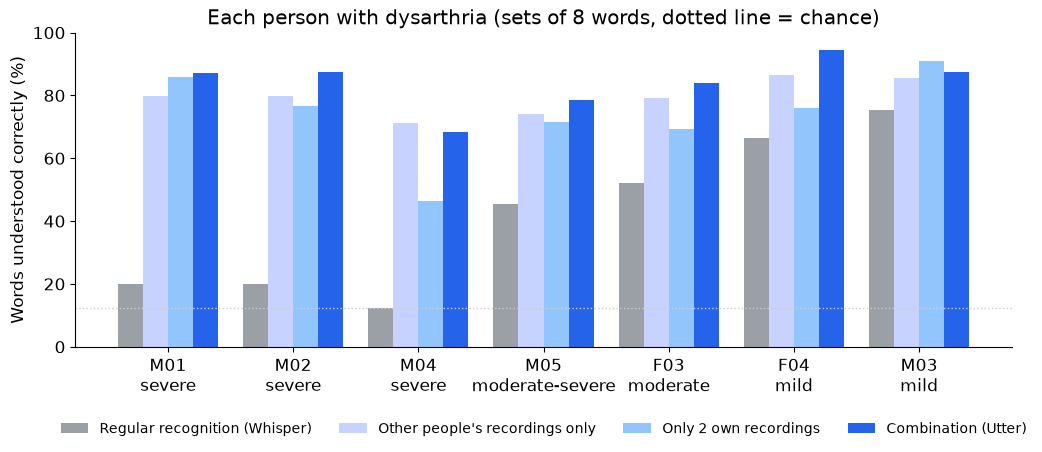

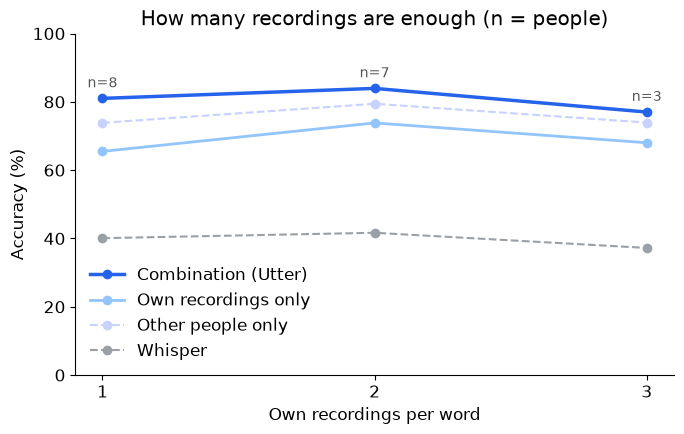

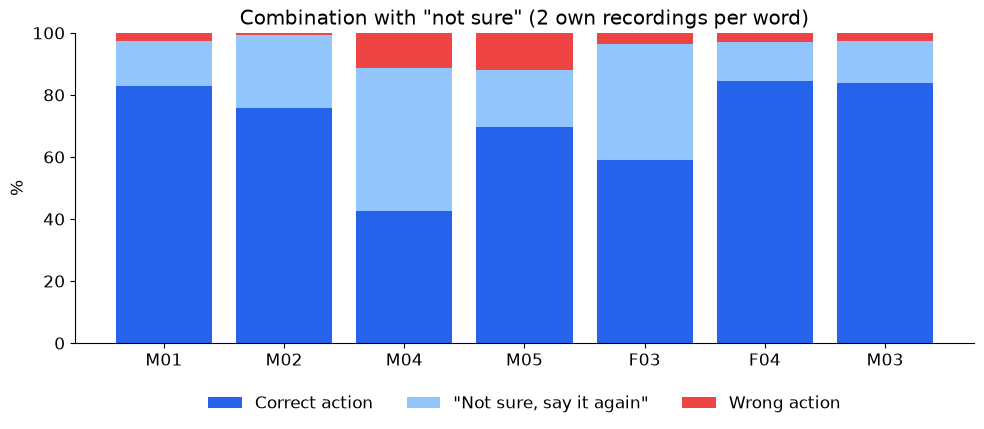

In [12]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, MID, LIGHT = "#9aa0a6", "#2563eb", "#93c5fd", "#c7d2fe"

# 1) Each person with dysarthria: Whisper vs others vs own vs combination
P = Dref
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(P)); w = 0.2
ax.bar(x - 1.5 * w, P.whisper * 100, w, color=GREY, label="Regular recognition (Whisper)")
ax.bar(x - 0.5 * w, P.general * 100, w, color=LIGHT, label="Other people's recordings only")
ax.bar(x + 0.5 * w, P[f"personal_k{REF_SHOT}"] * 100, w, color=MID, label=f"Only {REF_SHOT} own recordings")
ax.bar(x + 1.5 * w, P.combined * 100, w, color=ACCENT, label="Combination (Utter)")
ax.axhline(100 / VOCAB_SIZE, color="#ccc", ls=":", lw=1)
ax.set_xticks(x, [f"{s}\n{v}" for s, v in zip(P.speaker, P.severity)])
ax.set_ylabel("Words understood correctly (%)"); ax.set_ylim(0, 100)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=10)
ax.set_title(f"Each person with dysarthria (sets of {VOCAB_SIZE} words, dotted line = chance)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/1_per_speaker.png", dpi=200); plt.show()

# 2) How many recordings are enough
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(SHOTS, [by_shot[k]["combined"] * 100 for k in SHOTS], "o-", color=ACCENT, lw=2.5, label="Combination (Utter)")
ax.plot(SHOTS, [by_shot[k]["personal"] * 100 for k in SHOTS], "o-", color=MID, lw=2, label="Own recordings only")
ax.plot(SHOTS, [by_shot[k]["general"] * 100 for k in SHOTS], "o--", color=LIGHT, label="Other people only")
ax.plot(SHOTS, [by_shot[k]["whisper"] * 100 for k in SHOTS], "o--", color=GREY, label="Whisper")
for k in SHOTS:
    ax.annotate(f"n={by_shot[k]['n_speakers']}", (k, by_shot[k]["combined"] * 100), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=10, color="#555")
ax.set_xticks(SHOTS); ax.set_xlabel("Own recordings per word"); ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100); ax.legend(frameon=False); ax.set_title("How many recordings are enough (n = people)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/2_recordings_needed.png", dpi=200); plt.show()

# 3) The "not sure" state
fig, ax = plt.subplots(figsize=(10, 4.5))
b1, b2, b3 = P.rej_correct * 100, P.rej_repeat * 100, P.rej_wrong * 100
ax.bar(x, b1, color=ACCENT, label="Correct action")
ax.bar(x, b2, bottom=b1, color=MID, label="\"Not sure, say it again\"")
ax.bar(x, b3, bottom=b1 + b2, color="#ef4444", label="Wrong action")
ax.set_xticks(x, P.speaker); ax.set_ylabel("%"); ax.set_ylim(0, 100)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title(f"Combination with \"not sure\" ({REF_SHOT} own recordings per word)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/3_not_sure.png", dpi=200); plt.show()

## 6. Export for the app and the video
`results.json` holds the numbers for the app and the presentation. `examples/` gets a few recordings where Whisper failed and our model didn't.

In [13]:
THRESHOLD = float(Dref.pthreshold.median())          # the app: own examples only
THRESHOLD_COMBINED = float(Dref.threshold.median())  # combination

examples = []
for s in ref:
    t = trial(s, REF_SHOT, np.random.default_rng(SEED), M_spk[s], *Mg_spk[s])
    for j in range(len(t["y"])):
        i = t["test_idx"][j]
        if t["cpred"][j] == t["y"][j] and df.whisper_ok[i] == False and t["cmargin"][j] >= THRESHOLD_COMBINED:
            r = df.loc[i]
            fn = f"{r.clip_id}_{r.label}.wav"
            sf.write(f"{OUT_DIR}/examples/{fn}", r.wav, SR)
            examples.append(dict(file=fn, speaker=s, severity=r.severity, word=r.label,
                                 whisper_heard=r.whisper_text, our_pred=str(t["cpred"][j]),
                                 confidence_margin=float(t["cmargin"][j]), vocab=[str(v) for v in t["vocab"]]))
            if sum(e["speaker"] == s for e in examples) >= 2:
                break

def clean_json(x):
    if isinstance(x, dict): return {k: clean_json(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [clean_json(v) for v in x]
    if isinstance(x, (float, np.floating)): return None if not np.isfinite(x) else round(float(x), 4)
    if isinstance(x, np.integer): return int(x)
    return x

out = dict(headline=headline, by_shot={str(k): v for k, v in by_shot.items()},
           threshold=THRESHOLD, best_layer=BEST_LAYER, layer_scores={str(k): v for k, v in layer_scores.items()},
           threshold_combined=THRESHOLD_COMBINED,
           method="dtw", app_takes=APP_TAKES, general_per_word=GENERAL_PER_WORD,
           shots=SHOTS, ref_shot=REF_SHOT, vocab_size=VOCAB_SIZE, n_repeats=N_REPEATS,
           emb_model=EMB_MODEL, asr_model=ASR_MODEL, sr=SR, trim_db=TRIM_DB,
           whisper_max_tokens=WHISPER_MAX_TOKENS, max_wrong=MAX_WRONG,
           data=dict(source="TORGO (Rudzicz, Namasivam & Wolff, 2012), Hugging Face abnerh/TORGO-database",
                     clips=int(len(df)), words=int(df.label.nunique()), dataset_rows=int(len(ds))),
           per_speaker=res.to_dict(orient="records"), examples=examples)
with open(f"{OUT_DIR}/results.json", "w", encoding="utf-8") as f:
    json.dump(clean_json(out), f, ensure_ascii=False, indent=2)
print(f"Saved: {OUT_DIR}/results.json, {len(examples)} example recordings in examples/")
display(pd.DataFrame(examples)[["speaker", "word", "whisper_heard", "our_pred"]] if examples else "no examples")

if IN_COLAB:
    import shutil
    shutil.make_archive("/content/slysim_te", "zip", "/content", "slysim_te")
    from google.colab import files; files.download("/content/slysim_te.zip")

Saved: C:\ACTIVE\slysim-te\outputs/results.json, 11 example recordings in examples/


,speaker,word,whisper_heard,our_pred
0,M01,air,And,air
1,M01,spark,I,spark
2,M02,yes,Yeah.,yes
3,M02,sip,Fier,sip
4,M04,sip,hip,sip
5,M04,pat,Bye bye bye.,pat
6,M05,slip,shit,slip
7,M05,air,Ewww.,air
8,F03,sip,That's it.,sip
9,M03,spark,SPART,spark


## 7. Live demo (Gradio)
Record each command 3 times, then speak and the model recognises it. Runs only with `RUN_DEMO = True`. The full app (Utter) is in `app/`.

In [14]:
if RUN_DEMO:
    import gradio as gr

    def wav_from_gradio(a):
        if a is None:
            return None
        sr, y = a
        y = np.asarray(y, dtype=np.float32)
        if y.ndim > 1:
            y = y.mean(1)
        if np.abs(y).max() > 1.0:
            y = y / 32768.0
        return to_16k_trimmed(y, sr)

    live_frames = lambda wav: unit(embed_frames(wav, [BEST_LAYER])[BEST_LAYER])
    status_md = lambda d: "**Enrolled:** " + (", ".join(f"{c}: {len(d[c])}×" for c in COMMANDS if d.get(c)) or "nothing yet")

    def add_sample(cmd, audio, d):
        wav = wav_from_gradio(audio)
        if wav is None:
            return d, status_md(d) + "  \n⚠️ Record something first.", None
        d = dict(d); d[cmd] = d.get(cmd, []) + [live_frames(wav)]
        return d, status_md(d), None

    def recognize(audio, d):
        wav = wav_from_gradio(audio)
        vocab = [c for c in COMMANDS if d.get(c)]
        if wav is None or len(vocab) < 2:
            return "Enroll at least two commands, then record.", ""
        f = live_frames(wav)
        Dw = np.array([[min(dtw_from_sim(f @ e.T) for e in d[c]) for c in vocab]])
        pred, margin = decide(Dw, vocab)
        global w_model
        if "w_model" not in globals():
            w_model = WhisperForConditionalGeneration.from_pretrained(ASR_MODEL, dtype=w_dtype).to(device).eval()
        heard = f"A regular assistant heard: \"{whisper_text([wav])[0]}\""
        if margin[0] < THRESHOLD:
            return "## Not sure, please say it again.", heard
        return f"# {pred[0].upper()}", heard

    with gr.Blocks(title="Utter") as app:
        gr.Markdown("# Utter\nVoice control that adapts to your speech.")
        state = gr.State({})
        with gr.Row():
            cmd = gr.Dropdown(COMMANDS, value="yes", label="Command")
            rec = gr.Audio(sources=["microphone"], type="numpy", label="Record the command")
        save = gr.Button("Save example")
        status = gr.Markdown(status_md({}))
        test_rec = gr.Audio(sources=["microphone"], type="numpy", label="Say a command")
        go = gr.Button("Recognise", variant="primary")
        out_md, heard = gr.Markdown(), gr.Markdown()
        save.click(add_sample, [cmd, rec, state], [state, status, rec])
        go.click(recognize, [test_rec, state], [out_md, heard])
    app.launch(share=True)
else:
    print("Demo off (RUN_DEMO = False). The full app (Utter) is in app/.")

Demo off (RUN_DEMO = False). The full app (Utter) is in app/.
